# AS37 - The Hubble diagram for type Ia supernovae

In [1]:
# install the required libraries
%pip install astropy scipy emcee corner numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# load up the required libraries
import multiprocessing as mp
import numpy as np
import astropy
import emcee
import scipy
import corner
import matplotlib.pyplot as plt

## 4 - Analysis Procedure

### 4.1 Implementing the MCMC Framework

In [3]:
# Read the data from the SNLS data file
data = np.genfromtxt('SN1a_data.csv', delimiter=',', names=True)

# confirm that this has read the column headers correctly
print(data.dtype.names)

('OBJECT_ID', 'z', 'log_z', 'flux', 'flux_error', 'stretch', 'stretch_error', 'color', 'color_error', 'miu', 'miu_error', 'extinction', 'extinction_error')


In [4]:
# extract necessary information from the data, including alll of the errors

redshift = data['z']

extinction = data['extinction']
extinction_err = data['extinction_error']

obs_mag = data['flux']
obs_mag_err = data['flux_error']

Here, I will assume that the value of $H_0 = 70 km s^{-1} Mpc^{-1}$

In [5]:
H0 = 70

#### Sampler likelihood functions

In [6]:
# create functions for the sampler to use
def model_magnitude(params, z, E):
    # Calculates the expected apparent magnitude for each supernova given a trial set of cosmological parameters
    # Inputs:
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter) and m_abs (absolute magnitude of a type Ia supernova) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    # Outputs:
    #    -> exp_app: the expected apparent magnitude of the supernova

    Om0, m_abs = params
    cosmo = astropy.cosmology.FlatLambdaCDM(H0=H0, Om0 = Om0) # create a model of a flat universe based off of the given parameters
    
    D_L = cosmo.luminosity_distance(z) # calculate the luminoisty distance D_L using the given redshift values
    if np.any(D_L < 0):
        print('NEGATIVE')
    
    exp_app = m_abs + 5*np.log10(D_L.to_value('pc')) - 5 + E # needed to remove the Mpc dimension from D_L
    return exp_app

In [7]:
def log_likelihood(params, z, E, app_mag, app_mag_err):
    # Calculates the log-likelihood, ln P(data | model), that we obtain the data we have given that the universe follows the model we are assuming.
    # This quantifies the goodness of fit between the model and the data
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter) and m_abs (absolute magnitude of a type Ia supernova) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    chi2 = 0
    model_mag = model_magnitude(params, z, E)
    for i in range(redshift.size):
        chi2 += (app_mag[i] - model_mag[i])**2 / app_mag_err[i]**2 # based off the gaussian distribution we are assuming
    
    lnP = -0.5 * chi2 # note that we do not need the constant as it is the same for all trial parameters, so disappears when comparing them
    return lnP

In [8]:
def log_prior(params):
    # Calculates ln P(model), imposing prior knowledge on the parameters, eg their restricted values, such that the walkers cannot walk into forbidden regions.
    # If a region is forbidden, returns ln(0) = -inf, else returns ln(1) = 0
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter) and m_abs (absolute magnitude of a type Ia supernova) (stored in an iterable)
    # Ouptut:
    #    -> ln P(model), the logarithm of the likelihood that the parameters agree with imposed prior knowledge
    Om0 = params[0]

    # Know that the matter density must be greater than 0 to be physical
    if 0.0 < Om0 < 1.0:
        return 0
    else:
        return -np.inf

In [9]:
def log_probability(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters (stored in an iterable) (can be either (Om0, m_abs) or (Om0, m_abs, Ode0))
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood(params, z, E, app_mag, app_mag_err)

## Task 1: Flat Universe Model and Sampler Convergence

### Initialize the emcee sampler

In [56]:
# Initialize the emce sampler

ndim = 2
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.29, -19.3]) # Om0, m_abs
start_pos = initial_guess + 1e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    sampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:52<00:00,  9.60it/s]


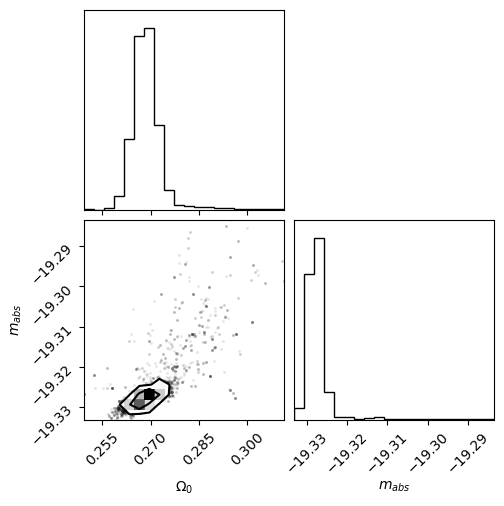

In [57]:
plt.close('all')
flat_samples = sampler.get_chain(flat=True)
samples = sampler.get_chain() # has the shape (nsteps, nwalkers, ndim)
corner.corner(flat_samples, labels = [r'$\Omega_0$', r'$m_{abs}$']);

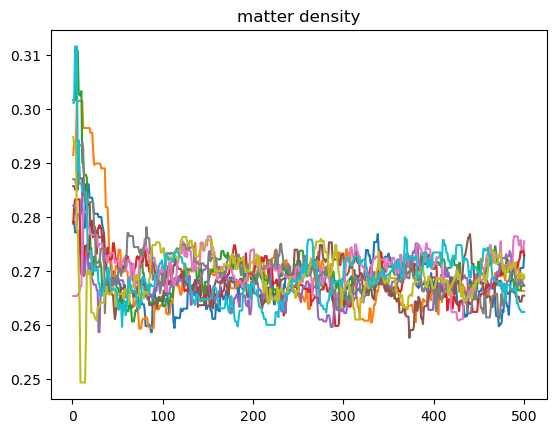

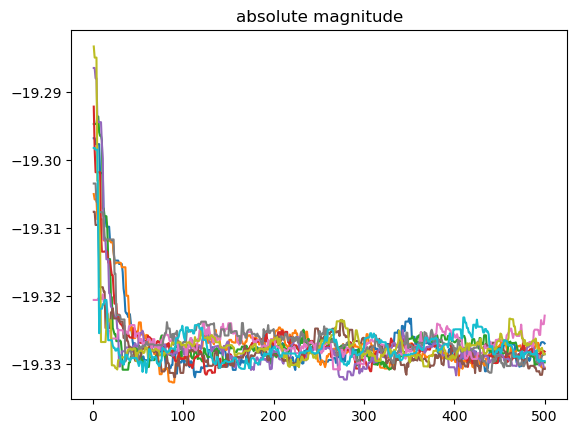

In [58]:
# plot the path of each walker for Om0 and m_abs against step

steps = np.arange(1, nsteps + 1)
n=10
fig1, axs1 = plt.subplots()
fig2, axs2 = plt.subplots()
for j in range(n):
    samples_Om0 = samples[:, j, 0]
    samples_m_abs = samples[:, j, 1]
    
    axs1.plot(steps, samples_Om0)
    axs1.set_title('matter density')

    axs2.plot(steps, samples_m_abs)
    axs2.set_title('absolute magnitude')

The burn-in phase appears to last for the first 50 steps .Now, I will update the initial positions of the walkers to more closely match the best-fit values, and improve the corner plot by discarding the burn-in phase

In [59]:
# set the initial positions to be closer to best-fit values
better_guess = np.array([0.27, -19.33])
new_start = better_guess + 1e-3*np.random.randn(nwalkers, ndim)

n_steps = 2000

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    sampler2 = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    sampler2.run_mcmc(new_start, nsteps, progress=True) # last argument shows the progress bar
    

100%|██████████| 500/500 [00:51<00:00,  9.80it/s]


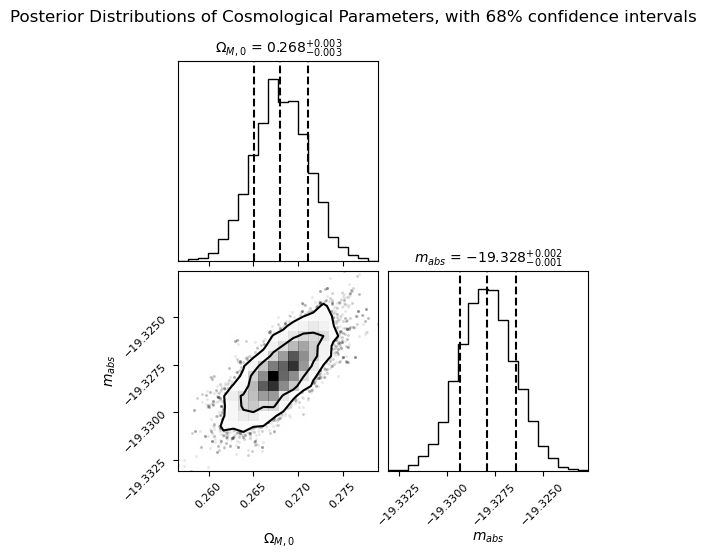

In [60]:
# again plot the new corner plots, then walker graphs

plt.close('all')
flat_samples2 = sampler2.get_chain(discard=30, flat=True)
samples2 = sampler2.get_chain() # has the shape (nsteps, nwalkers, ndim)

# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(flat_samples2,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

From the plots, it can be seen that for the matter density parameter $\Omega_{M,0}$, the best fit value is $0.268 \pm 0.003$.
For the absolute magnitude of a type Ia supernova, $m_{abs}$, the best fit value is $-19.328 \pm 0.001$.


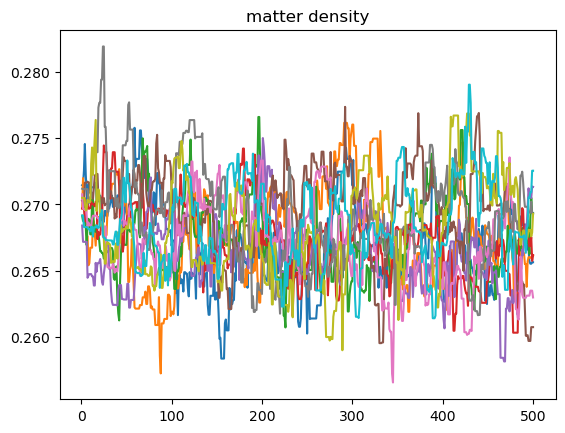

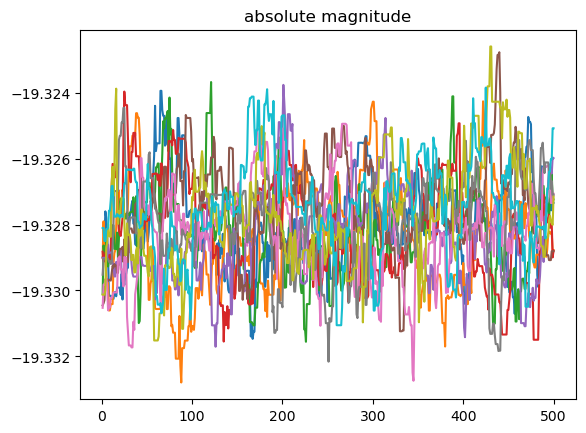

In [61]:
# now again plot the path of each walker for Om0 and m_abs against step for the improved walkers

steps = np.arange(1, nsteps + 1)
n=10
fig3, axs3 = plt.subplots()
fig4, axs4 = plt.subplots()
for j in range(n):
    samples_Om0 = samples2[:, j, 0]
    samples_m_abs = samples2[:, j, 1]
    
    axs3.plot(steps, samples_Om0)
    axs3.set_title('matter density')

    axs4.plot(steps, samples_m_abs)
    axs4.set_title('absolute magnitude')

On a larger scale, the walkers converge much quicker, and the contours appear much smoother

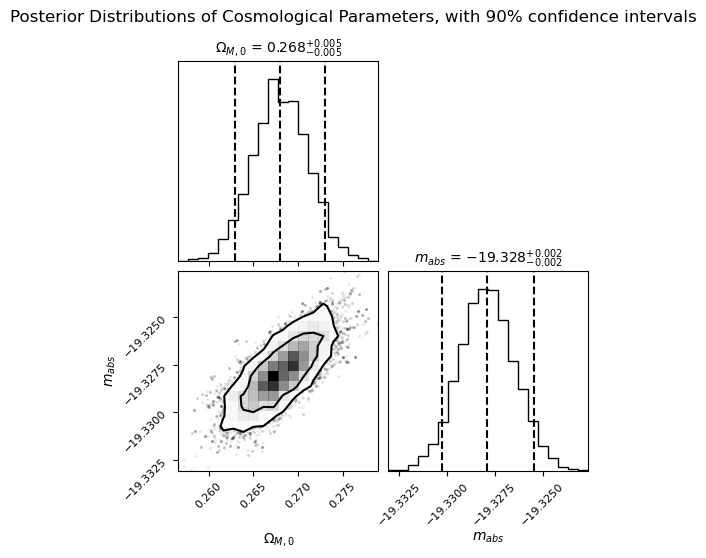

In [62]:
# now display the 90% confidence interval
plt.close('all')

fig2 = corner.corner(flat_samples2,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$'],
                    quantiles=[0.05, 0.5, 0.95], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig2.suptitle('Posterior Distributions of Cosmological Parameters, with 90% confidence intervals', y=1.02) # add a main title to all the plots and move it up

for ax in fig2.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

From the graph, the 90% confidence interval for the matter density parameter, $\Omega_{M,0}$, is $\pm 0.005$, and the interval for $m_{abs}$ is $\pm 0.002$.

The above 2D contour map on the off-diagonal axis shows how the 90% contour is still centererd about the median, and follows roughly the same shape compared to the 68% contour. It encloses a higher area since it contains more points

### Plotting observed magnitudes against expected apparent magnitudes from the best fit model

Text(0.5, 0, 'observed apparent magnitude')

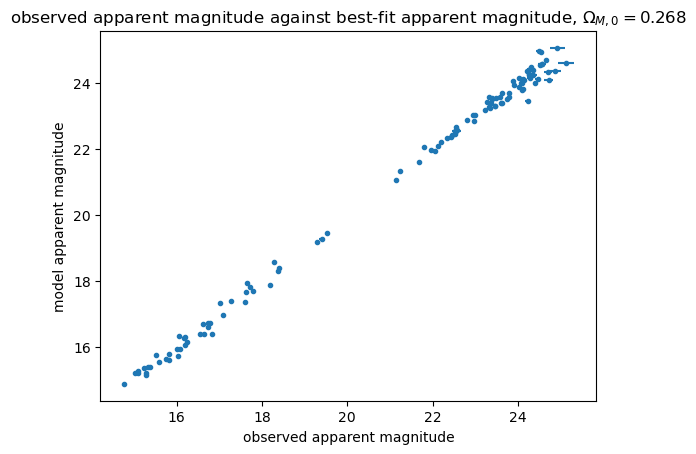

In [11]:
fig1_1, axs1_1 = plt.subplots()

best_fit_params = (0.268, -19.328)
axs1_1.errorbar(obs_mag, model_magnitude(best_fit_params, redshift, extinction), xerr=obs_mag_err, fmt='.');
axs1_1.set_title('observed apparent magnitude against best-fit apparent magnitude, '+ r'$\Omega_{M,0} = 0.268$')
axs1_1.set_ylabel('model apparent magnitude')
axs1_1.set_xlabel('observed apparent magnitude')

### Plotting predictions for model with $\Omega_{M,0} = 1$

Text(0.5, 0, 'observed apparent magnitude')

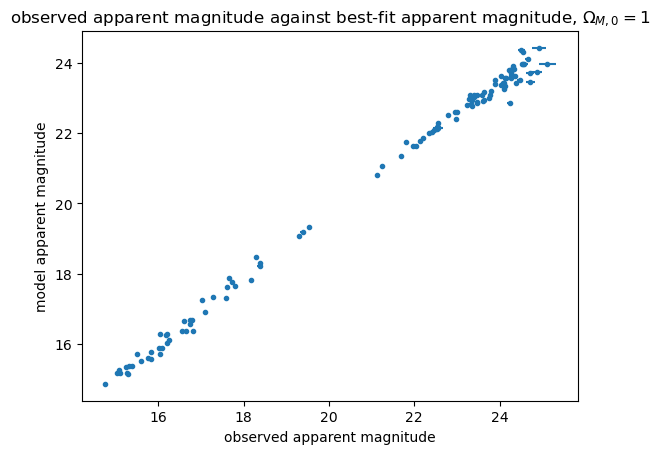

In [12]:
fig1_2, axs1_2 = plt.subplots()

new_params = (1.00, -19.328)
axs1_2.errorbar(obs_mag, model_magnitude(new_params, redshift, extinction), xerr=obs_mag_err, fmt='.');
axs1_2.set_title('observed apparent magnitude against best-fit apparent magnitude, '+ r'$\Omega_{M,0} = 1$')
axs1_2.set_ylabel('model apparent magnitude')
axs1_2.set_xlabel('observed apparent magnitude')

#### Plotting the difference between the 2 graphs

Text(0.5, 0, 'observed apparent magnitude')

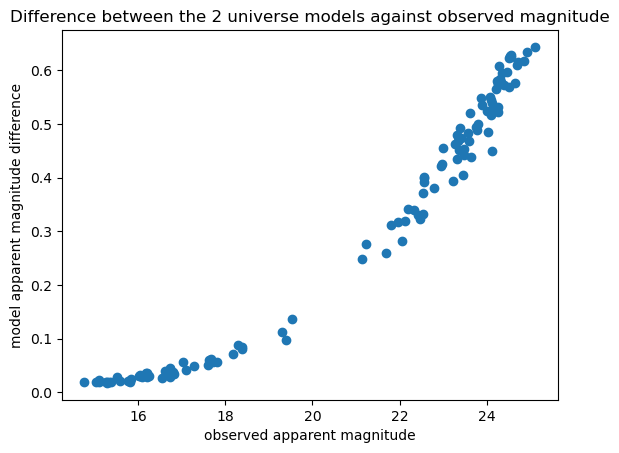

In [16]:
difference = model_magnitude(best_fit_params, redshift, extinction) - model_magnitude(new_params, redshift, extinction)
plt.scatter(obs_mag, difference)
plt.title('Difference between the 2 universe models against observed magnitude')
plt.ylabel('model apparent magnitude difference')
plt.xlabel('observed apparent magnitude')

From this plot, we can see that the 2 models have a very similar shape, but deviate slightly more with increasing observed apparent magnitude (which relates to an increased luminosity distance). This implies that for our universe, the models predict very similar results for nearby supernovae, but the effects of different matter densities only takes effect at greater luminosity distances away.

## Task 2: Non-Flat Universe Model

Now we are introducing a third parameter due to dark energy, $\Omega_{\Lambda ,0}$, and fitting for this

In [65]:
# create new functions based off the new universe model we are using (effectively just changing model_magnitude and telling other functions to use new version)
def model_magnitude_2(params, z, E):
    # Calculates the expected apparent magnitude for each supernova given a trial set of cosmological parameters
    # Inputs:
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and Ode0 (present day cosmological constant) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    # Outputs:
    #    -> exp_app: the expected apparent magnitude of the supernova

    Om0, m_abs, Ode0 = params
    cosmo = astropy.cosmology.LambdaCDM(H0=H0, Om0 = Om0, Ode0 = Ode0) # create a model of a flat universe based off of the given parameters
    
    D_L = cosmo.luminosity_distance(z) # calculate the luminoisty distance D_L using the given redshift values
    
    exp_app = m_abs + 5*np.log10(D_L.to_value('pc')) - 5 + E # needed to read D_L in parsecs
    return exp_app

def log_likelihood_2(params, z, E, app_mag, app_mag_err):
    # Calculates the log-likelihood, ln P(data | model), that we obtain the data we have given that the universe follows the model we are assuming.
    # This quantifies the goodness of fit between the model and the data
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and Ode0 (present day cosmological constant) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    chi2 = 0
    model_mag = model_magnitude_2(params, z, E)
    for i in range(redshift.size):
        chi2 += (app_mag[i] - model_mag[i])**2 / app_mag_err[i]**2 # based off the gaussian distribution we are assuming
    
    lnP = -0.5 * chi2 # note that we do not need the constant as it is the same for all trial parameters, so disappears when comparing them
    return lnP

def log_probability_2(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and Ode0 (present day cosmological constant) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood_2(params, z, E, app_mag, app_mag_err)

In [66]:
# Configure and run the emcee sampler for 3 parameters using the new likelihood function

ndim = 3
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.27, -19.3, 0.73]) # Om0, m_abs, Ode0
start_pos = initial_guess + 1e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    nonflatsampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_2,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    nonflatsampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:49<00:00, 10.14it/s]


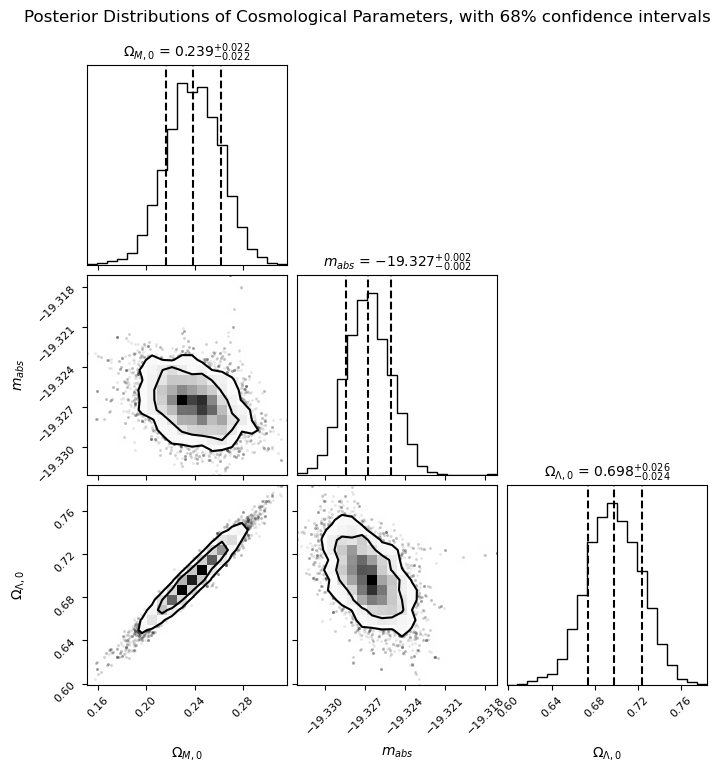

In [67]:
# plot the new corner plots
plt.close('all')
flat_nonflatsamples = nonflatsampler.get_chain(discard=30, flat=True)
nonflatsamples = nonflatsampler.get_chain() # has the shape (nsteps, nwalkers, ndim)

# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(flat_nonflatsamples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

The best fitting parameter values can be read from the titles of the graphs. We can see that $\Omega_{M,0} + \Omega_{\Lambda,0} = 0.937_{-0.047}^{+0.051}$ (can be rounded to $0.94 \pm 0.05$). This is just out of the range of being consistent with a flat universe, as the worst case uncertainty puts us to within 1.2% of being flat, since from the sum rule, $\Omega_{k,0}$ will be non-zero.

In the $\Omega_{M,0} - \Omega_{\Lambda,0}$ plane, the contour is so elongated due to the fact that these two parameters can easily compensate for eachother if one is changed, since the data does not place many constraints on these 2 parameters. Therefore, they are both free to move in order to keep the curvature energy density in the sum rule close to the best fit value.

## Task 3: Evolving Dark Energy Model

We return back to the flat universe model from the first task, but allow the dark energy equation of state, $w_0$, to vary. Like the previous tasks, I will make new functions to accomodate the updated universe model.

In [68]:
def model_magnitude_w(params, z, E):
    # Calculates the expected apparent magnitude for each supernova given a trial set of cosmological parameters
    # Inputs:
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    # Outputs:
    #    -> exp_app: the expected apparent magnitude of the supernova

    Om0, m_abs, w0 = params
    cosmo = astropy.cosmology.FlatwCDM(H0=H0, Om0=Om0, w0=w0) # create a model of a flat universe based off of the given parameters
    
    D_L = cosmo.luminosity_distance(z) # calculate the luminoisty distance D_L using the given redshift values
    
    exp_app = m_abs + 5*np.log10(D_L.to_value('pc')) - 5 + E # needed to read D_L in parsecs
    return exp_app

def log_likelihood_w(params, z, E, app_mag, app_mag_err):
    # Calculates the log-likelihood, ln P(data | model), that we obtain the data we have given that the universe follows the model we are assuming.
    # This quantifies the goodness of fit between the model and the data
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    chi2 = 0
    model_mag = model_magnitude_w(params, z, E)
    for i in range(redshift.size):
        chi2 += (app_mag[i] - model_mag[i])**2 / app_mag_err[i]**2 # based off the gaussian distribution we are assuming
    
    lnP = -0.5 * chi2 # note that we do not need the constant as it is the same for all trial parameters, so disappears when comparing them
    return lnP

def log_prior_w(params):
    # Calculates ln P(model), imposing prior knowledge on the parameters, eg their restricted values, such that the walkers cannot walk into forbidden regions.
    # If a region is forbidden, returns ln(0) = -inf, else returns ln(1) = 0
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter) and m_abs (absolute magnitude of a type Ia supernova) (stored in an iterable)
    # Ouptut:
    #    -> ln P(model), the logarithm of the likelihood that the parameters agree with imposed prior knowledge
    Om0, m_abs, w0 = params

    Om0_prior = True
    w0_prior = True

    # Know that the matter density must be greater than 0 to be physical
    if 0.0 < Om0 < 1.0:
        Om0_prior = True
    else:
        Om0_prior = False

    # given an appropriate range for w0
    if -2 < w0 < -0.5:
        w0_prior = True
    else:
        w0_prior = False

    if Om0_prior and w0_prior:
        return 0.0
    return -np.inf

def log_probability_w(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior_w(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood_w(params, z, E, app_mag, app_mag_err)

In [69]:
# Configure and run the emcee sampler for 3 parameters using the new likelihood function (decided to use a slightly larger initial spread)

ndim = 3
nwalkers = 100
nsteps = 400
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.2, -19.33, -1.5]) # Om0, m_abs, w0 values given
start_pos = initial_guess + 1e-1 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    wsampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_w,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    wsampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

  0%|          | 0/400 [00:00<?, ?it/s]/home/jovyan/.local/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 400/400 [02:12<00:00,  3.01it/s]


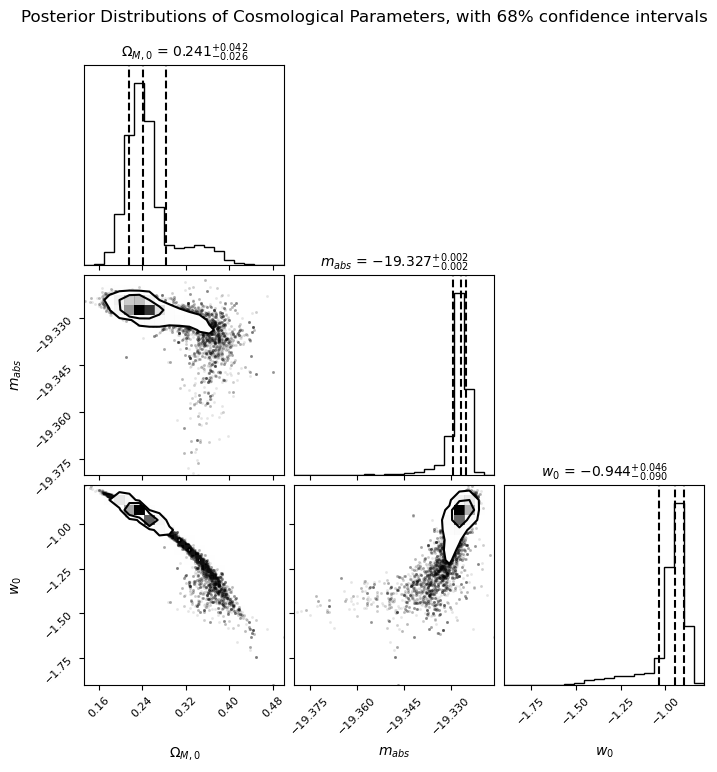

In [70]:
# plot the new corner plots
plt.close('all')
wsamples = wsampler.get_chain(discard=30, flat=True)
whole_wsamples = wsampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(wsamples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

The plots show that the best fitting value of $w_0$ is $-0.940^{0.045}_{0.056}$, so the lower bound value of $w_0$ is $-0.996$, which rounds to $-1.00$ to 2dp, therefore we can say that the best fit value of $w_0$ from this model agrees with there being a cosmological constant.

### Producing the walker plots for dark energy evolution

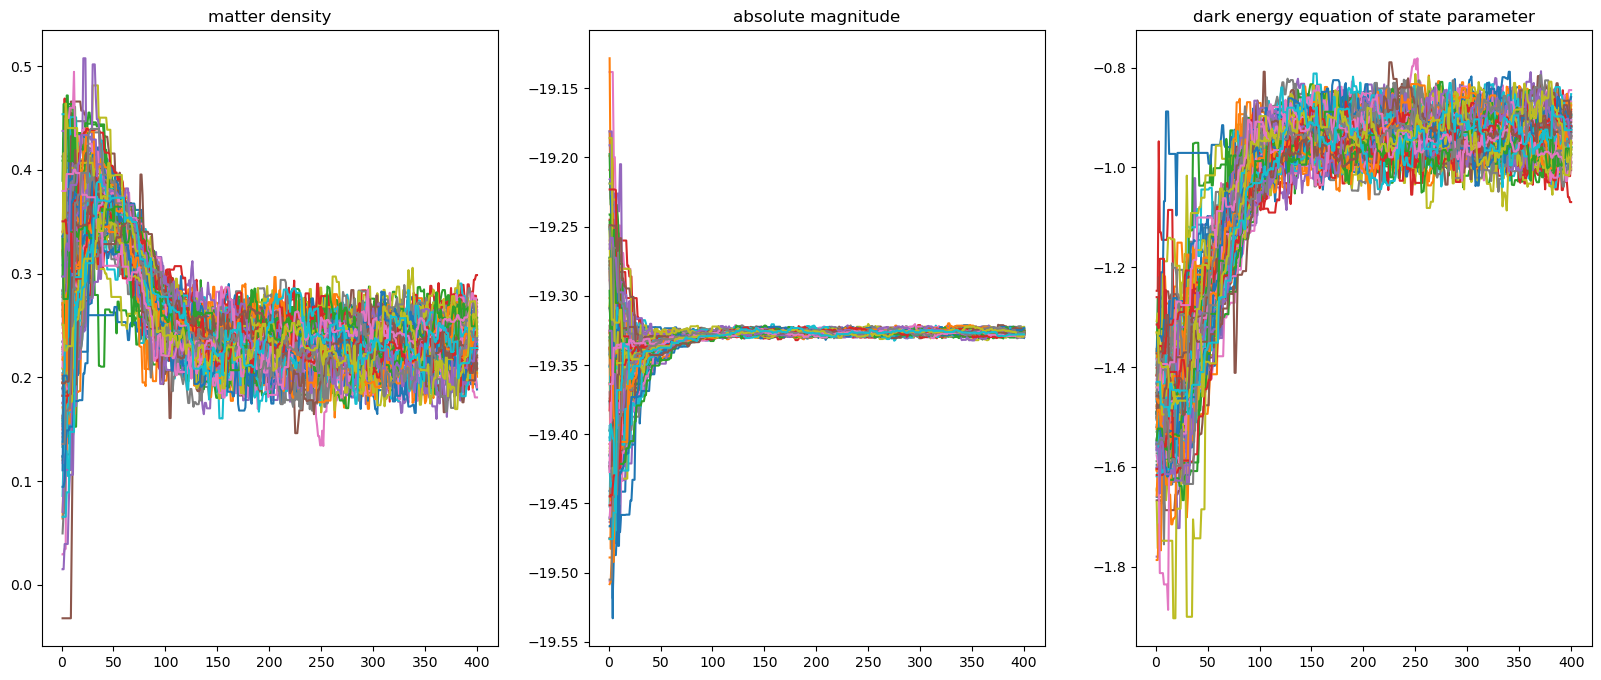

In [71]:
steps = np.arange(1, nsteps + 1)
n=100
figw, axsw = plt.subplots(1, 3, figsize=(20,8))

for j in range(n):
    samples_Om0 = whole_wsamples[:, j, 0]
    samples_m_abs = whole_wsamples[:, j, 1]
    samples_w = whole_wsamples[:, j, 2]
    
    axsw[0].plot(steps, samples_Om0)
    axsw[0].set_title('matter density')

    axsw[1].plot(steps, samples_m_abs)
    axsw[1].set_title('absolute magnitude')

    axsw[2].plot(steps, samples_w)
    axsw[2].set_title('dark energy equation of state parameter')

The walkers to not appear to all diverge by the end, though it does take some a while to move from a certain position, which likely marks a local maximum. However, since all of the walkers are able to resolve themselves, it is not necessary to rerun the simulation with improved starting positions.

## Task 4: General Model with a CMB prior

### Considering the most general case of a non flat universe with a varaible dark energy equation of state, fitting the 4 parameters $\Omega_{M,0}, m_{abs}, \Omega_{\Lambda,0},$ and $w_0$.

In [21]:
def model_magnitude_gen(params, z, E):
    # Calculates the expected apparent magnitude for each supernova given a trial set of cosmological parameters
    # Inputs:
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    # Outputs:
    #    -> exp_app: the expected apparent magnitude of the supernova

    Om0, m_abs, Ode0, w0 = params
    cosmo = astropy.cosmology.wCDM(H0=H0, Om0=Om0, Ode0=Ode0, w0=w0) # create a model of a flat universe based off of the given parameters
    
    D_L = cosmo.luminosity_distance(z) # calculate the luminoisty distance D_L using the given redshift values
    
    exp_app = m_abs + 5*np.log10(D_L.to_value('pc')) - 5 + E # needed to read D_L in parsecs
    return exp_app

def log_likelihood_gen(params, z, E, app_mag, app_mag_err):
    # Calculates the log-likelihood, ln P(data | model), that we obtain the data we have given that the universe follows the model we are assuming.
    # This quantifies the goodness of fit between the model and the data
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    chi2 = 0
    model_mag = model_magnitude_gen(params, z, E)
    for i in range(len(z)):
        chi2 += (app_mag[i] - model_mag[i])**2 / app_mag_err[i]**2 # based off the gaussian distribution we are assuming
    
    lnP = -0.5 * chi2 # note that we do not need the constant as it is the same for all trial parameters, so disappears when comparing them
    return lnP

def log_prior_gen(params):
    # Calculates ln P(model), imposing prior knowledge on the parameters, eg their restricted values, such that the walkers cannot walk into forbidden regions.
    # If a region is forbidden, returns ln(0) = -inf, else returns ln(1) = 0
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    # Ouptut:
    #    -> ln P(model), the logarithm of the likelihood that the parameters agree with imposed prior knowledge
    Om0, m_abs, Ode0, w0 = params

    Om0_prior = True
    w0_prior = True

    # Know that the matter density must be greater than 0 to be physical
    if 0.0 < Om0 < 1.0:
        Om0_prior = True
    else:
        Om0_prior = False

    # given an appropriate range for w0
    if -2 < w0 < -0.5:
        w0_prior = True
    else:
        w0_prior = False

    # given a gaussian spread range for Ok0, so can sub into sum rule to get constraint on Om0 + Ode0 being around 0.999 with a standard deviation of 0.002, then return the log of the probability.
    log_cmb_prior = -0.5 * (((0.999 - (Om0 + Ode0)) / 0.002)**2)
    
    if Om0_prior and w0_prior:
        return log_cmb_prior
    return -np.inf

def log_probability_gen(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior_gen(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood_gen(params, z, E, app_mag, app_mag_err)

In [73]:
# Configure and run the emcee sampler for 4 parameters using the new likelihood function

ndim = 4
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.7, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    gensampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_gen,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    gensampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:53<00:00,  9.36it/s]


#### Without adding in the constraint on the $\Omega_{k,0}$ term, we get poorly constrained plots that hold no real shape.

![4 parameter plot without new constraint](poorly_constrained_4_param_plot.png)

### 4 parameter plot:

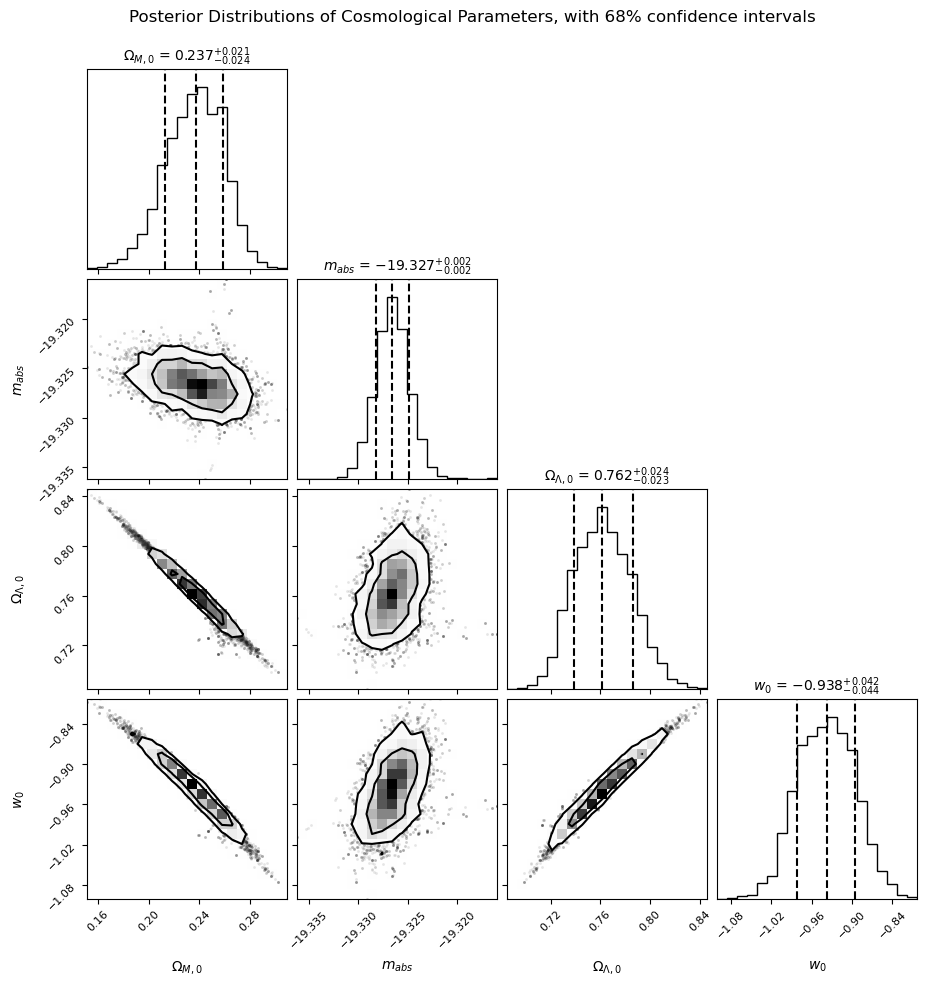

In [96]:
# plot the new corner plots
plt.close('all')
gensamples = gensampler.get_chain(discard=30, flat=True)
whole_gensamples = gensampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(gensamples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

#### These plots are a lot better constrained due to the priors, with $m_{abs}$ ($-19.327$) and $w_0$ ($-0.943$) agreeing with the previous results. While $\Omega_{M,0}$ agrees with the previous 2 results very well ($0.240$), $\Omega_{\Lambda,0}$ has increased from $0.698$ to $0.759$, just outside of each result's error bounds. This new result predicts a value of $\Omega_{k,0} = 0.001 \pm 0.001$, meaning that this universe is or is very close to being flat. As well as this, the dark energy equation of state also suggests that there is nearly, but not quite, a cosmological constant.

### Investigating the effect of changing the error on $\Omega_{k,0}$

Here, I will create new function for the prior and likelihood finders with adjustable errors to see when the data becomes unconstrained and what happens if the error is too low

In [39]:
Ok0_err = 0.1 # the standard deviation of Ok0

def log_prior_err(params):
    # Calculates ln P(model), imposing prior knowledge on the parameters, eg their restricted values, such that the walkers cannot walk into forbidden regions.
    # If a region is forbidden, returns ln(0) = -inf, else returns ln(1) = 0
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    # Ouptut:
    #    -> ln P(model), the logarithm of the likelihood that the parameters agree with imposed prior knowledge
    Om0, m_abs, Ode0, w0 = params

    Om0_prior = True
    w0_prior = True

    # Know that the matter density must be greater than 0 to be physical
    if 0.0 < Om0 < 1.0:
        Om0_prior = True
    else:
        Om0_prior = False

    # given an appropriate range for w0
    if -2 < w0 < -0.5:
        w0_prior = True
    else:
        w0_prior = False

    # given a gaussian spread range for Ok0, so can sub into sum rule to get constraint on Om0 + Ode0 being around 0.999 with a standard deviation of 0.002, then return the log of the probability.
    log_cmb_prior = -0.5 * (((0.999 - (Om0 + Ode0)) / Ok0_err)**2)
    
    if Om0_prior and w0_prior:
        return log_cmb_prior
    return -np.inf

def log_probability_err(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior_err(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood_gen(params, z, E, app_mag, app_mag_err)

In [40]:
# Configure and run the emcee sampler for 4 parameters using the new likelihood function

ndim = 4
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.7, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    errsampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_err,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    errsampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:55<00:00,  9.05it/s]


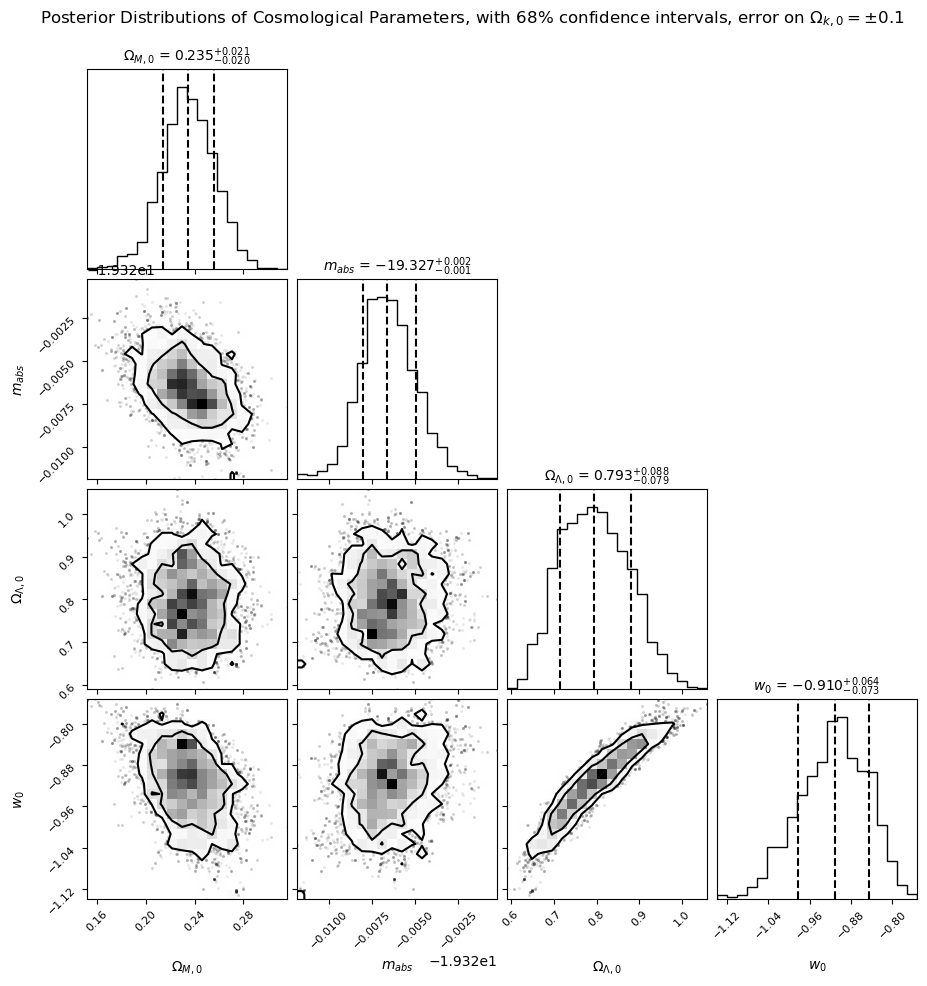

In [41]:
# plot the new corner plots
plt.close('all')
errsamples = errsampler.get_chain(discard=30, flat=True)
whole_errsamples = errsampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(errsamples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals, error on ' + r'$\Omega_{k,0} = \pm$' + f'{Ok0_err}', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

In [43]:
# fig.savefig('4_param_100_err.png')

<div style="display: flex; justify-content: space-between; text-align:center;">
    
 <div style="width: 32%;">
     <img src="4_param_040_err.png" width="100%">
     <p>Error = 0.040</p>
 </div>

 <div style="width: 32%;">
     <img src="4_param_100_err.png" width="100%">
     <p>Error = 0.100</p>
 </div>

  <div style="width: 32%;">
     <img src="4_param_150_err.png" width="100%">
     <p>Error = 0.150</p>
 </div>

</div>


From the plots, we can see the effect of increasing the error on $\Omega_{k,0}$ on the constraining of the corner plots. In particular, when looking at the histogram for $\Omega_{\Lambda,0}$, we can see that somewhere between the error being 0.100 and 0.150, the gaussian shape of the histogram disappears almost entirely as the histogram emphasises the prior on the varaibles more so than the shape of the probability map.

### Significantly reducing the error on $\Omega_{k,0}$

In [46]:
Ok0_err2 = 0.0001 # the standard deviation of Ok0

def log_prior_err2(params):
    # Calculates ln P(model), imposing prior knowledge on the parameters, eg their restricted values, such that the walkers cannot walk into forbidden regions.
    # If a region is forbidden, returns ln(0) = -inf, else returns ln(1) = 0
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    # Ouptut:
    #    -> ln P(model), the logarithm of the likelihood that the parameters agree with imposed prior knowledge
    Om0, m_abs, Ode0, w0 = params

    Om0_prior = True
    w0_prior = True

    # Know that the matter density must be greater than 0 to be physical
    if 0.0 < Om0 < 1.0:
        Om0_prior = True
    else:
        Om0_prior = False

    # given an appropriate range for w0
    if -2 < w0 < -0.5:
        w0_prior = True
    else:
        w0_prior = False

    # given a gaussian spread range for Ok0, so can sub into sum rule to get constraint on Om0 + Ode0 being around 0.999 with a standard deviation of 0.002, then return the log of the probability.
    log_cmb_prior = -0.5 * (((0.999 - (Om0 + Ode0)) / Ok0_err)**2)
    
    if Om0_prior and w0_prior:
        return log_cmb_prior
    return -np.inf

def log_probability_err2(params, z, E, app_mag, app_mag_err):
    # This will be the main function called by the sampler, returning the total log-posterior probability (i.e. the likelihood that we have the model given the data),
    # by summing the log-prior and log-likelihood, implementing Baye's Theorem.
    # Inputs: 
    #    -> params: the trial set of cosmological parameters, Om0 (present day matter density parameter), m_abs (absolute magnitude of a type Ia supernova),
    #       Ode0 (present day dark energy density),and w0 (dark energy equation of state) (stored in an iterable)
    #    -> z: redshift values
    #    -> E: extinction values
    #    -> app_mag: the observed apparent magnitudes of the supernovae
    #    -> app_mag_err: the errors on the observed apparent magnitudes
    # Output:
    #    -> ln(probability), the posterior probability


    lp = log_prior_err2(params) # the log-prior probability
    
    # If one of the probablities is zero, return ln(0) = -inf
    if not np.all(np.isfinite(lp)):
        return -np.inf

    # Else return the sum of the two probabilities:
    return lp + log_likelihood_gen(params, z, E, app_mag, app_mag_err)

In [47]:
# Configure and run the emcee sampler for 4 parameters using the new likelihood function

ndim = 4
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.7, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    err2sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_err2,
        args=(redshift, extinction, obs_mag, obs_mag_err), # appends these arguments always when changing the parameter values
        pool=pool)

    err2sampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:54<00:00,  9.20it/s]


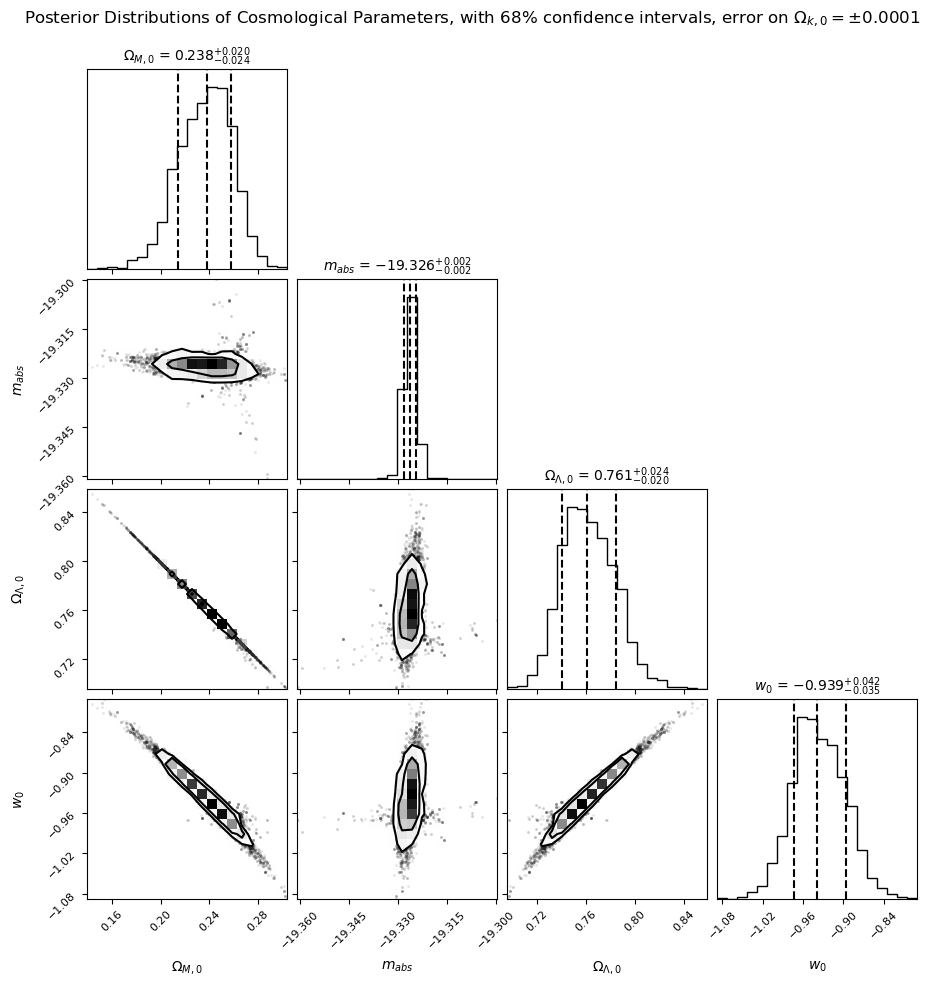

In [48]:
# plot the new corner plots
plt.close('all')
err2samples = err2sampler.get_chain(discard=30, flat=True)
whole_err2samples = err2sampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(err2samples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle('Posterior Distributions of Cosmological Parameters, with 68% confidence intervals, error on ' + r'$\Omega_{k,0} = \pm$' + f'{Ok0_err}', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

Singificanlty reducing the error essentially removes the possibility of $\Omega_{M,0} + \Omega_{\Lambda,0}$ from shifting, further narrowing their possible values. This is shown as the 2D plots become much thinner, reducing possible spread around the degeneracy line of the exact solution.

# 5) Further Investigations

## 5.1 The Importance of the Redshift Lever Arm

Text(0.5, 0, 'Redshift')

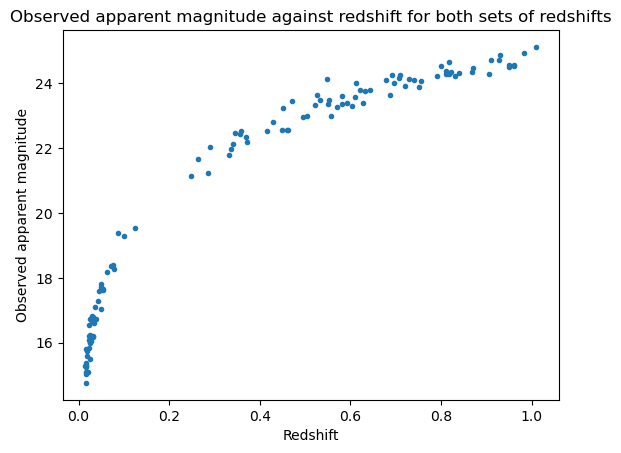

In [5]:
plt.scatter(redshift, obs_mag, marker='.', linestyle='None'); # just show the points
plt.title('Observed apparent magnitude against redshift for both sets of redshifts')
plt.ylabel('Observed apparent magnitude')
plt.xlabel('Redshift')

Can see that the supernovae are split into groups above and below 0.2, so we will split them apart and work with them separately (44 supernovae below $z=0.2$, 71 above)

### Analyse the lower redshifts first:


In [80]:
ndim = 4
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.7, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    low_sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_gen,
        args=(redshift[:44], extinction[:44], obs_mag[:44], obs_mag_err[:44]), # appends these arguments always when changing the parameter values
        pool=pool)

    low_sampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:52<00:00,  9.52it/s]


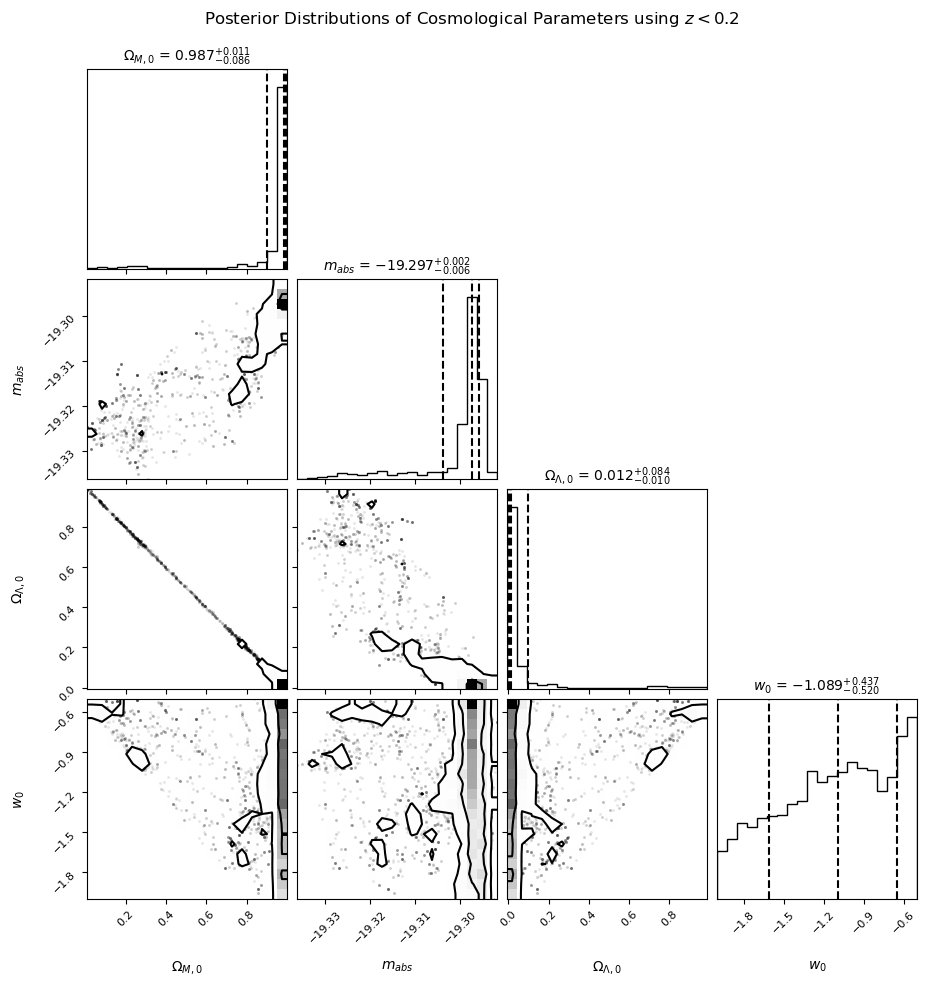

In [81]:
# plot the new corner plots
plt.close('all')
low_samples = low_sampler.get_chain(discard=30, flat=True)
whole_low_samples = low_sampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(low_samples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle(r'Posterior Distributions of Cosmological Parameters using $z < 0.2$', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

#### Out of interest, will take a look at the walker plots

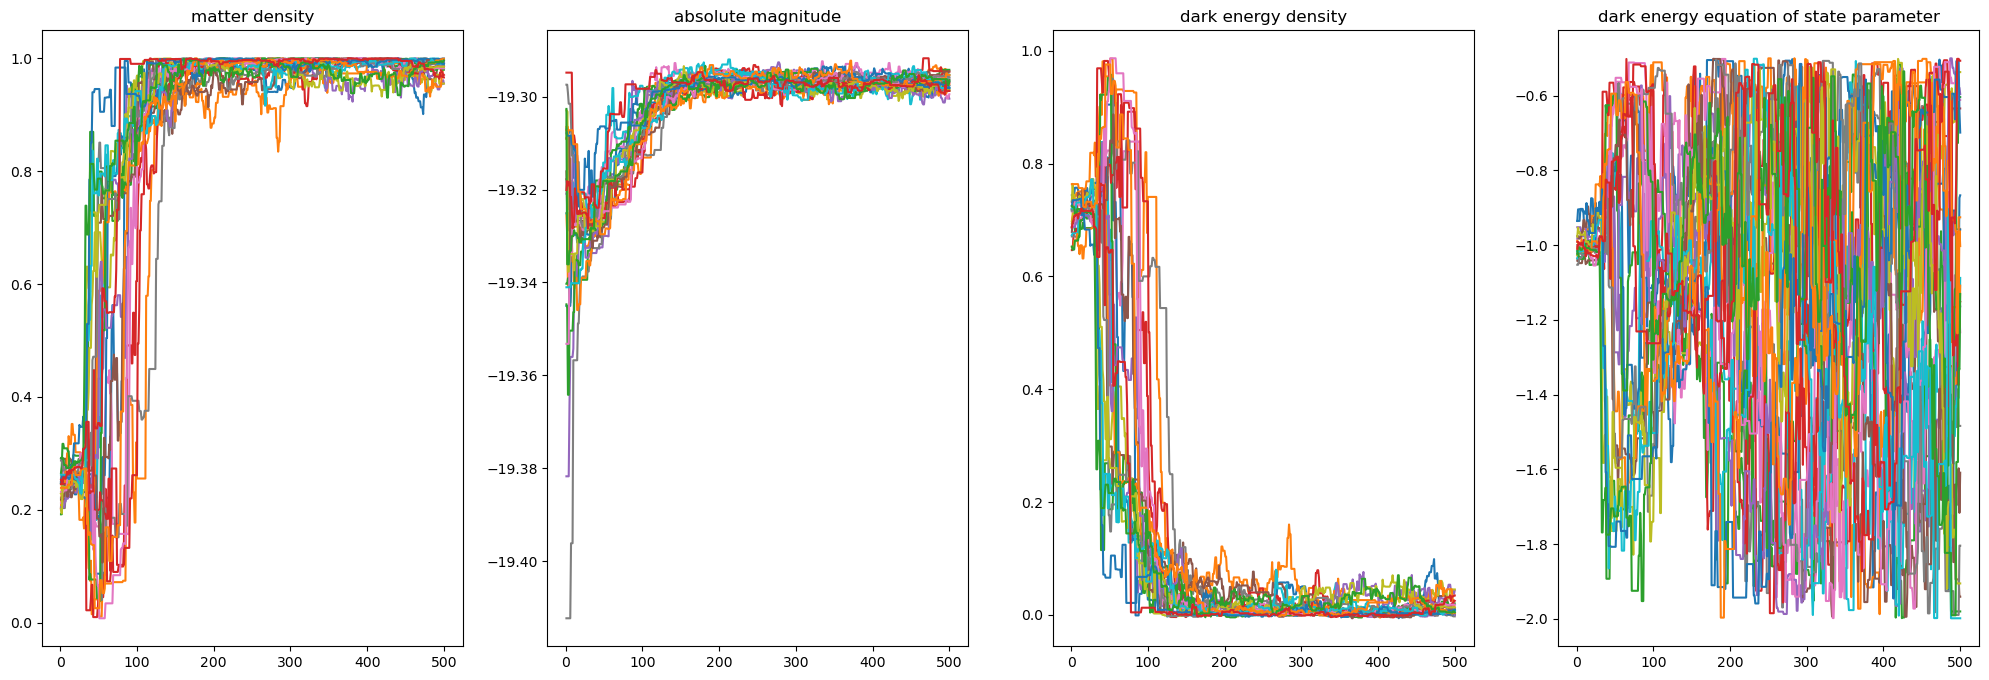

In [82]:
steps = np.arange(1, nsteps + 1)
n=24
figlow, axslow = plt.subplots(1, 4, figsize=(25,8))

for j in range(n):
    samples_Om0 = whole_low_samples[:, j, 0]
    samples_m_abs = whole_low_samples[:, j, 1]
    samples_Ode0 = whole_low_samples[:, j, 2]
    samples_w = whole_low_samples[:, j, 3]
    
    axslow[0].plot(steps, samples_Om0)
    axslow[0].set_title('matter density')

    axslow[1].plot(steps, samples_m_abs)
    axslow[1].set_title('absolute magnitude')

    axslow[2].plot(steps, samples_Ode0)
    axslow[2].set_title('dark energy density')

    axslow[3].plot(steps, samples_w)
    axslow[3].set_title('dark energy equation of state parameter')

This confirms that the walkers did converge for the first 3 parameters

### Now analyse the higher redshifts

In [83]:
ndim = 4
nwalkers = 24
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.7, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    high_sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_gen,
        args=(redshift[44:], extinction[44:], obs_mag[44:], obs_mag_err[44:]), # appends these arguments always when changing the parameter values
        pool=pool)

    high_sampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [00:56<00:00,  8.91it/s]


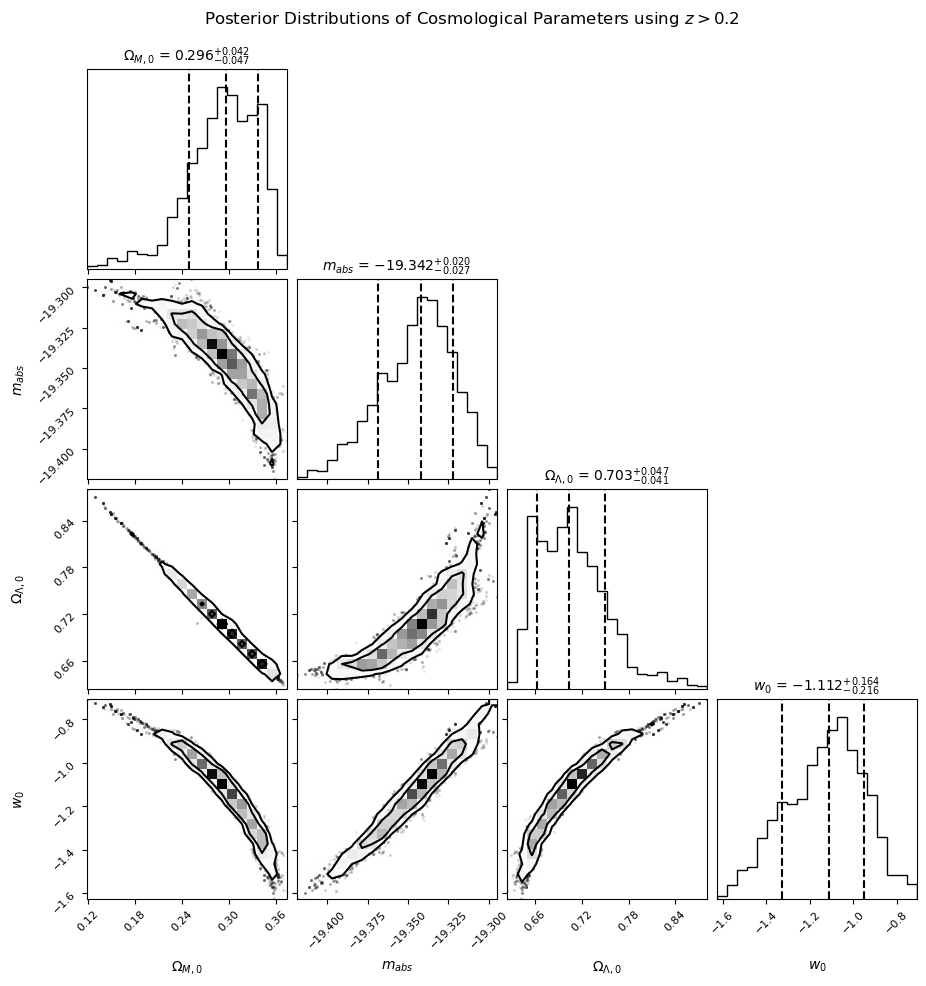

In [84]:
# plot the new corner plots
plt.close('all')
high_samples = high_sampler.get_chain(discard=30, flat=True)
whole_high_samples = high_sampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(high_samples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle(r'Posterior Distributions of Cosmological Parameters using $z > 0.2$', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

### Analysing the plots:

The plots that look at the lower redshifts show how $w_0$ is completely unrestrained, and the dark energy density, $\Omega_{\Lambda,0}$, has a best fit value that is basically zero (considering the errors). This is expected since the lower redshifts will represent supernovae closer to us, so the effect of dark energy is miniscule over these scales. Since it is so small, the value of  $w_0$ is unconstrained, and due to the low value of $\Omega_{\Lambda,0}$, $\Omega_{M,0}$ approaches 1.
The higher redshift plots show high degeneracy in the off-diagonal plots and unconstrained peaks, due to the fact that there is no data to create a local anchor whcih might say how $m_{abs}$ should be regardless of cosmology. The other different parameters can change to counter this affect, creating degeneracies in which different combinations all work the same way (i.e. there is no starting value to create a baseline for the values)
Therefore, we can conclude that a wide range of redshifts is crucial for constraining a cosmological model

## 5.2 Forecasting Constraints from Future Surveys

#### Generating a mock catalogue of supernovae with the same number of data points as the one used here. After, I will combine it with the real dataset to create one double the size.

In [59]:
# Establishing a 'true' universe based off of best fit parameters
# Using the flatwCDM model:
true_Om0 = 0.239
true_m_abs = -19.327
true_Ode0 = 0.761
true_w0 = -0.95

In [60]:
# Generate new supernovae with a set of redshifts (and extinctions) by randomly sampling the existing set (with replacement)

new_redshifts = np.zeros(115) # 115 is the size of the original data set
new_extinctions = np.zeros(115)

for i in range(115):
    index = np.random.randint(115)
    new_redshifts[i] = redshift[index]
    new_extinctions[i] = extinction[index]
print(new_redshifts.size)
print(redshift.size)

115
115


In [61]:
# For each new supernovae redshift, calculate a 'true' apparent magnitude, based on the 'true' universe created

new_cosmo = astropy.cosmology.FlatwCDM(H0=H0, Om0=true_Om0, w0=true_w0)
D_l = new_cosmo.luminosity_distance(new_redshifts)
true_app_mag = true_m_abs + 5*np.log10(D_l.to_value('pc')) - 5 + new_extinctions

In [62]:
# add gaussian error to the perfect apparent magnitudes to simulate noise:
#   To do this, in order to not add the maximum error to each value, for each model point, I will randomly pick an observed
#   magnitude error from the original data set, then create a gaussian based with the selected error as the standard deviation,
#   and sample from there.

selected_errors = np.random.choice(obs_mag_err, size=115) # create a list of 115 randomly selected samples
added_noise = np.random.normal(scale=selected_errors) # sample from a gaussian of std = selected_errors for each point
new_app_mags = true_app_mag + added_noise

In [63]:
# combine the two data sets into a larger set

large_redshifts = np.concatenate((redshift, new_redshifts))
large_extinctions = np.concatenate((extinction, new_extinctions))
large_obs_mags = np.concatenate((obs_mag, new_app_mags))

# selected_errors acts as the new obs_mag_err
large_obs_mag_err = np.concatenate((obs_mag_err, selected_errors))
print(large_obs_mag_err.size)

230


#### Analysing the new larger sample

Before I run the fit, I predict that the parameter errors will become lower as the error on the mean scales as $N^{1/2}$. As the new data is drawn from the old distribution, the mean is the same for redshift and apparent magnitude, so the peak should be sharper by a factor of around $\sqrt{2}$.

For reference, on the original 4-parameter fit, the uncertanties were:

| Parameter | Uncertainty |
|-----------|-------------|
| $\Omega_{M,0}$ | $\pm 0.023$ |
| $m_{abs}$ | $\pm 0.002$ |
| $\Omega_{\Lambda,0}$ | $\pm 0.024$ |
| $w_0$ | $\pm 0.045$ |

##### Find the best fit parameters and plot:

In [64]:
# Configure and run the emcee sampler for 4 parameters using the new likelihood function

ndim = 4
nwalkers = 100
nsteps = 500
# note that for now, these are arbitrary, except for ndim

# guess some starting values, and add some variation to them for each walker
initial_guess = np.array([0.24, -19.33, 0.759, -1.00]) # Om0, m_abs, Ode0, w0 values given
start_pos = initial_guess + 3e-2 * np.random.randn(nwalkers, ndim) # create a gaussian spread of start positions about the initial guess

with mp.Pool() as pool: # create the multiprocessing pool to use multiple CPU cores at once
    largesampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_probability_gen,
        args=(large_redshifts, large_extinctions, large_obs_mags, large_obs_mag_err), # passes these arguments always when changing the parameter values
        pool=pool)

    largesampler.run_mcmc(start_pos, nsteps, progress=True) # last argument shows the progress bar

100%|██████████| 500/500 [03:04<00:00,  2.71it/s]


#### Plotting the new data

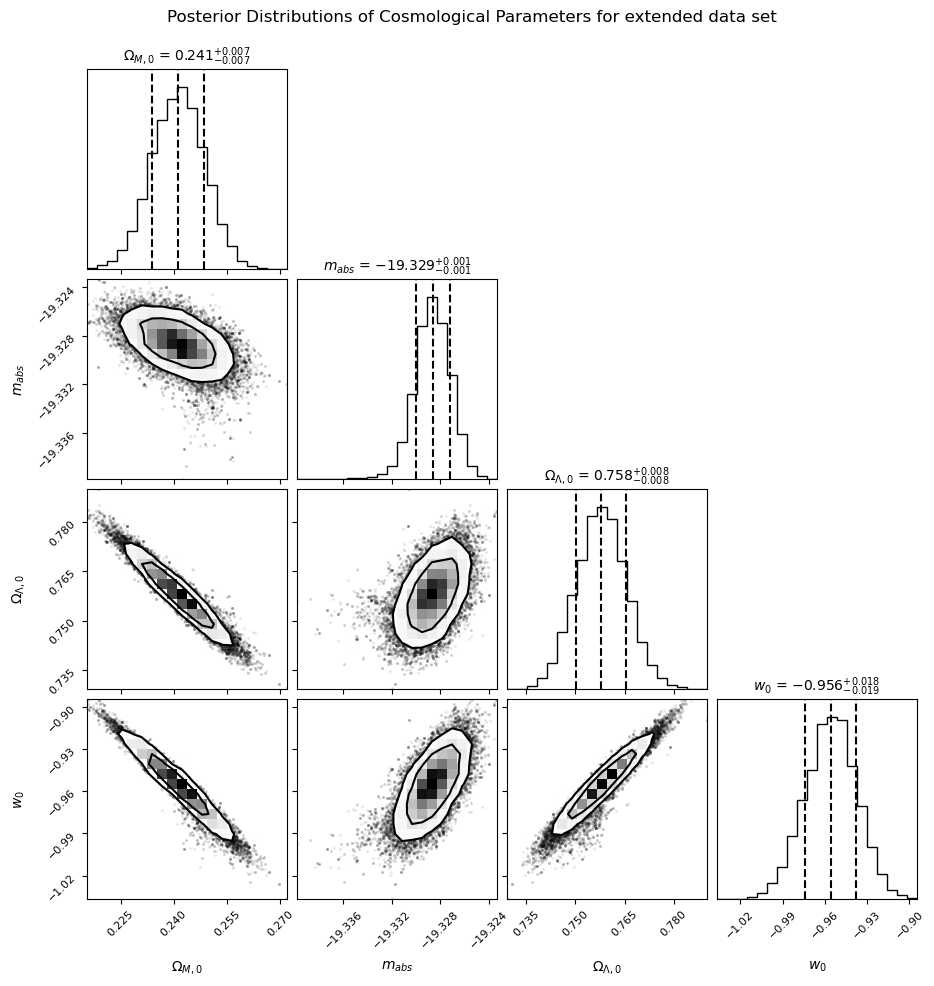

In [65]:
# plot the new corner plots
plt.close('all')
large_samples = largesampler.get_chain(discard=30, flat=True)
whole_large_samples = largesampler.get_chain()
# plot the corner graphs to show the median and the 1 sigma uncertainity (the distance between the 16th and 84th percentiles)

fig = corner.corner(large_samples,
                    labels=[r'$\Omega_{M,0}$', r'$m_{abs}$', r'$\Omega_{\Lambda,0}$', r'$w_0$'],
                    quantiles=[0.16, 0.5, 0.84], 
                    show_titles=True, # display the medians
                    title_kwargs={'fontsize': 10}, # set font size of the titles
                    title_fmt='.3f', # set to display 4dp
                    levels=[0.68, 0.90]); # change the contours on the off-diagonal 2D contour 
fig.suptitle(r'Posterior Distributions of Cosmological Parameters for extended data set', y=1.02) # add a main title to all the plots and move it up

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=8) # reduce the axis tick mark label sizes

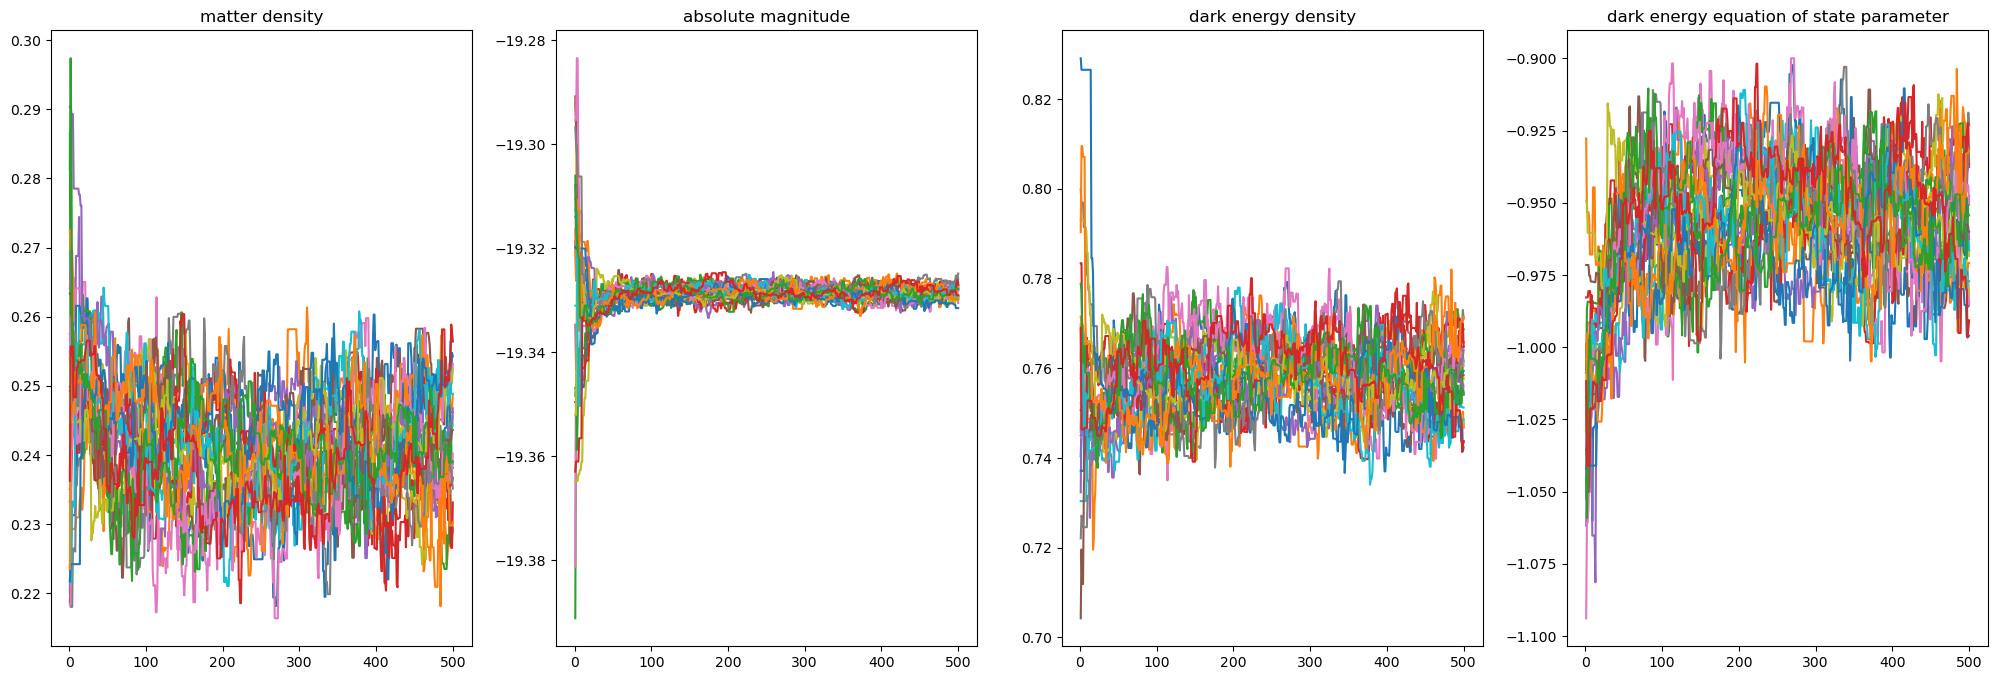

In [66]:
steps = np.arange(1, nsteps + 1)
n=24
figlow, axslow = plt.subplots(1, 4, figsize=(25,8))

for j in range(n):
    samples_Om0 = whole_large_samples[:, j, 0]
    samples_m_abs = whole_large_samples[:, j, 1]
    samples_Ode0 = whole_large_samples[:, j, 2]
    samples_w = whole_large_samples[:, j, 3]
    
    axslow[0].plot(steps, samples_Om0)
    axslow[0].set_title('matter density')

    axslow[1].plot(steps, samples_m_abs)
    axslow[1].set_title('absolute magnitude')

    axslow[2].plot(steps, samples_Ode0)
    axslow[2].set_title('dark energy density')

    axslow[3].plot(steps, samples_w)
    axslow[3].set_title('dark energy equation of state parameter')

We can see here that the uncertanties have indeed decreased:

| Parameter | Old Uncertainty | New Uncertainty | % Change |
|-----------|-----------------|-----------------|----------|
| $\Omega_{M,0}$ | $\pm 0.023$ | $\pm 0.011$ | $47\%$ |
| $m_{abs}$ | $\pm 0.002$ | $\pm 0.001$ | $50\%$ |
| $\Omega_{\Lambda,0}$ | $\pm 0.024$ | $\pm 0.012$ | $50\%$ |
| $w_0$ | $\pm 0.045$ | $\pm 0.023$ | $51\%$ |

From here, we can conclude that the 1-sigma uncertainty values have decreased by around a factor of 2, which goes against my prediction of it reducing by a factor of $\sqrt{2} \approx 1.41$. This could be due to the fact that we can see that the mean values of all the variables have changed by a couple of percentage points, meaning that there there will have to be more spread to memaningfully adjust the position of the mean, which is what has happened. If the model sampled more reshfits from either the higher or lower region, this could have had an effect on the new mean positions if the effect of dark energy at higher redshifts is either under or overrepresented. Either way, this may create a new distribution than the original one, so the uncertainties would not decrease as if we had simply duplicated the original data set.

# Conclusion

| Parameter | Value from CMB prior |
|-----------|----------------------|
| $\Omega_{M,0}$ | $0.237^{+0.021}_{-0.024}$ |
| $\Omega_{\Lambda,0}$ | $0.762^{+0.024}_{-0.023}$ |
| $m_{abs}$ | $-19.327^{+0.002}_{-0.002}$ |
| $w_0$ | $-0.938^{+0.042}_{-0.044}$ |

When looking at the CMB prior best-fit parameters, we can see that the energy of the universe mostly comes from dark energy, making up roughly $76\%$ of all energy, and matter making up only the minority. According to this data, since $w_0 \neq -1$ even to within the error bounds, dark energy is not constant and so it evolves (which doesn't agree with real life observation). The redshift lever arm in 5.1 supports this dark matter picture of the universe, since at greater redshifts, apparent magnitude increases with redshift at a lower rate than at recent times (lower redshifts), meaning the supernovae were moving away from us at a lower rate than would be predicted if we only looked at the lower redshift supernovae. This means that the rate of expansion of the universe has increased between these two time frames.

If we try to combine 2 datasets to derive a single set of cosmological parameters, then if one of the datasets had a systematic error in it (such as the possiblitiy that type Ia supernovae don't act as standard candles), then the peak in the data would appear in the wrong place, but may still be very narrow. The joint analysis would still contain the systematic error. In order to verify if this result is correct, it would be a good idea to try to use other observational methods not involving the type of data where you suspect the systematic error to be. If this also converges on the same peak, then this would support the original discovery.